# 2

## (a)

Let $X = G/\sqrt{n}$, where $G \in \mathbb{R}^{n\times n}$ has i.i.d. $\mathcal{N}(0,1)$ entries. 
Let the spin vector be $s \in \{-1,1\}^n$ and define the variance parameter as:
$$
    F(G)=\frac{1}{n}\log\sum_{s\in\{-1,1\}^n}
    \exp\left(\frac{1}{\sqrt n}s^\top Gs+h(s)\right).
$$
Then $F(G)=Z$. For every $i,j$,
$$
\begin{align*}
    \frac{\partial F}{\partial G_{ij}}
    &= \frac{1}{n\sqrt n}
    \frac{\sum_s s_i s_j\exp\left(\frac{1}{\sqrt n}s^\top Gs+h(s)\right)}
    {\sum_s\exp\left(\frac{1}{\sqrt n}s^\top Gs+h(s)\right)}.
\end{align*}
$$
The fraction is a weighted average of $s_is_j \in \{-1,1\}$, so
$$
    \left|\frac{\partial F}{\partial G_{ij}}\right| \leq \frac{1}{n\sqrt n}.
$$
Therefore,
$$
\begin{align*}
    \|\nabla F(G)\|_F^2
    &= \sum_{i,j=1}^n\left(\frac{\partial F}{\partial G_{ij}}\right)^2 \\
    &\leq n^2\left(\frac{1}{n\sqrt n}\right)^2 \\
    &= \frac{1}{n}.
\end{align*}
$$
Thus, after identifying $G$ with $\operatorname{vec}(G) \in \mathbb{R}^{n^2}$, 
$F$ is $1/\sqrt n$-Lipschitz. By the TIS inequality,
$$
    P[F(G)-EF(G)\geq t] \leq \exp\left(-\frac{t^2}{2(1/n)}\right)
    = e^{-nt^2/2}.
$$
Applying the same bound to $-F$ and taking a union bound gives
$$
    P[|Z-EZ|\geq t] \leq 2e^{-nt^2/2}, \qquad t\geq0.
$$

## (b)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from joblib import Parallel, delayed
from sklearn.linear_model import lasso_path
from threadpoolctl import threadpool_limits

n = 200
p = 500
k = 10
sigma = 1.0
T = 2000
c_values = np.array([0.1, 0.5, 1.0, 2.0])
lambda0 = sigma * np.sqrt(2 * np.log(p) / n)
alphas = c_values * lambda0

rng = np.random.default_rng(0)
X = rng.standard_normal((n, p))
beta_star = np.zeros(p)
support = rng.choice(p, size=k, replace=False)
beta_star[support] = rng.choice(np.array([-1.0, 1.0]), size=k)
mu = X @ beta_star

noise_seeds = np.random.SeedSequence(0).spawn(T)
print(f"lambda0 = {lambda0:.6f}")
print(f"support = {support.tolist()}")

lambda0 = 0.249291
support = [318, 88, 175, 69, 60, 252, 322, 425, 195, 360]


In [2]:

def run_trial(seed):
    trial_rng = np.random.default_rng(seed)
    epsilon = sigma * trial_rng.standard_normal(n)
    y = mu + epsilon

    alpha_desc = alphas[::-1]
    with threadpool_limits(limits=1):
        _, coefficients, _ = lasso_path(
            X,
            y,
            alphas=alpha_desc,
            max_iter=10000,
            tol=1e-8
        )

    coefficients = coefficients[:, ::-1]
    prediction_errors = np.linalg.norm(
        X @ (coefficients - beta_star[:, None]),
        axis=0
    )
    return prediction_errors

errors = np.vstack(
    Parallel(n_jobs=8, backend="loky", verbose=5)(
        delayed(run_trial)(seed) for seed in noise_seeds
    )
)

means = errors.mean(axis=0)
standard_deviations = errors.std(axis=0, ddof=1)
summary = pd.DataFrame({
    "c": c_values,
    "lambda": alphas,
    "mean(E_lambda)": means,
    "sd(E_lambda)": standard_deviations
})
summary

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:    2.6s
[Parallel(n_jobs=8)]: Done  64 tasks      | elapsed:    2.8s
[Parallel(n_jobs=8)]: Done 672 tasks      | elapsed:    4.6s
[Parallel(n_jobs=8)]: Done 1680 tasks      | elapsed:    7.4s
[Parallel(n_jobs=8)]: Done 2000 out of 2000 | elapsed:    8.2s finished


,c,lambda,mean(E_lambda),sd(E_lambda)
0,0.1,0.024929,11.016190,0.705715
1,0.5,0.124646,7.338829,0.906148
2,1.0,0.249291,11.807917,1.001842
3,2.0,0.498582,22.963668,1.012580


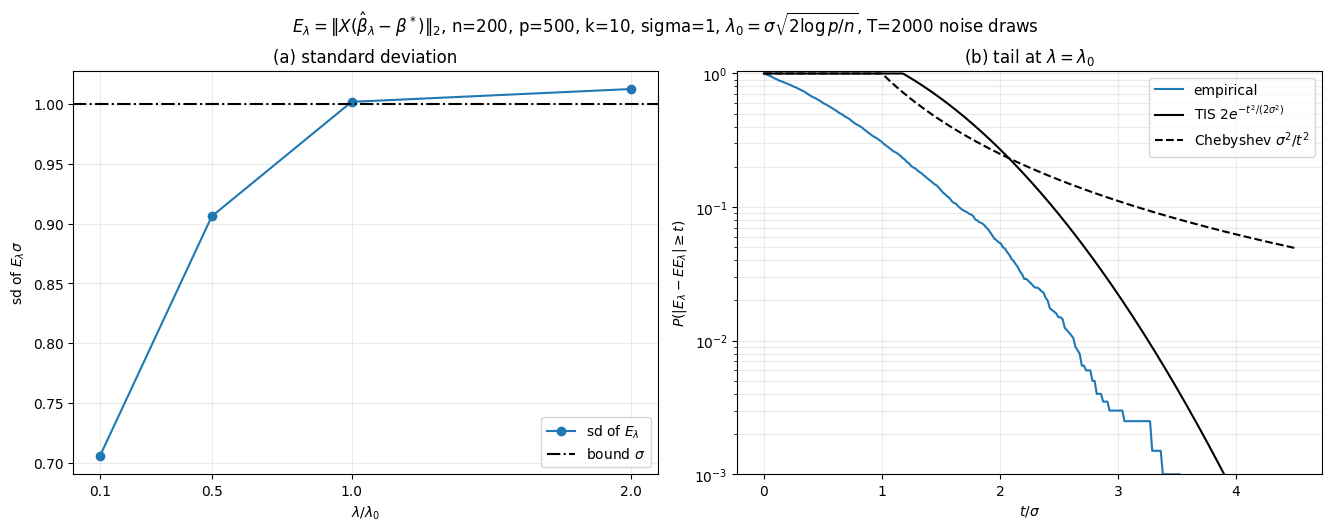

In [8]:
lambda0_index = np.where(c_values == 1.0)[0][0]
centered = np.abs(errors[:, lambda0_index] - means[lambda0_index])

t_grid = np.linspace(0.0, 4.5, 250)
empirical_tail = np.array([
    np.mean(centered >= t) for t in t_grid
])
tis_bound = np.minimum(1.0, 2 * np.exp(-(t_grid**2) / (2 * sigma**2)))
chebyshev_bound = np.ones_like(t_grid)
positive = t_grid > 0
chebyshev_bound[positive] = np.minimum(
    1.0,
    sigma**2 / t_grid[positive]**2
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(13.2, 5.2),
    layout="constrained"
)

axes[0].plot(c_values, standard_deviations, marker="o", label=r"sd of $E_\lambda$")
axes[0].axhline(sigma, linestyle="-.", label=r"bound $\sigma$", color="black")
axes[0].set_xlabel(r"$\lambda/\lambda_0$")
axes[0].set_ylabel(r"sd of $E_\lambda\sigma$")
axes[0].set_xticks(c_values)
axes[0].set_title("(a) standard deviation")
axes[0].grid(True, alpha=0.25)
axes[0].legend()

axes[1].plot(t_grid, empirical_tail, label="empirical")
axes[1].plot(t_grid, tis_bound, label=r"TIS $2e^{-t^2/(2\sigma^2)}$", color="black")
axes[1].plot(t_grid, chebyshev_bound, linestyle="--", label=r"Chebyshev $\sigma^2/t^2$", color="black")
axes[1].set_yscale("log")
axes[1].set_ylim(1e-3, 1.05)
axes[1].set_xlabel(r"$t/\sigma$")
axes[1].set_ylabel(r"$P(|E_\lambda-EE_\lambda|\geq t)$")
axes[1].set_title(r"(b) tail at $\lambda=\lambda_0$")
axes[1].grid(True, which="both", alpha=0.25)
axes[1].legend()

fig.suptitle(
    r"$E_\lambda=\|X(\hat\beta_\lambda-\beta^*)\|_2$, "
    f"n={n}, p={p}, k={k}, sigma={sigma:g}, "
    r"$\lambda_0 = \sigma\sqrt{2\log p/n}$, "
    f"T={T} noise draws"
)
plt.show()


In [9]:
t_chebyshev = sigma / np.sqrt(0.01)
t_tis = sigma * np.sqrt(2 * np.log(2 / 0.01))
t_empirical = np.quantile(centered, 0.99, method="higher")

thresholds = pd.DataFrame({
    "bound / tail": ["Chebyshev", "TIS", "empirical"],
    "t where tail reaches 0.01": [t_chebyshev, t_tis, t_empirical]
})
thresholds

,bound / tail,t where tail reaches 0.01
0,Chebyshev,10.000000
1,TIS,3.255247
2,empirical,2.626360


i. Let $f(\epsilon)=a+\langle u,\epsilon\rangle$ with $\|u\|_2=1$ and $\epsilon\sim\mathcal{N}(0,\sigma^2I_n)$. 
Then
$$
    \langle u,\epsilon\rangle \sim \mathcal{N}(0,\sigma^2\|u\|_2^2)
    =\mathcal{N}(0,\sigma^2),
$$
so
$$
    \operatorname{sd}(f(\epsilon))=\sigma.
$$
Now suppose $P$ is an orthogonal projection of rank $r$. By rotational invariance,
$$
    \|P\epsilon\|_2 \overset{d}{=} \sigma\chi_r.
$$
Since $E[\chi_r^2]=r$ and
$$
    E[\chi_r]=\sqrt{2}\frac{\Gamma((r+1)/2)}{\Gamma(r/2)},
$$
we have
$$
\begin{align*}
    \operatorname{Var}(\|P\epsilon\|_2)
    &=\sigma^2\left[r-2\left(\frac{\Gamma((r+1)/2)}{\Gamma(r/2)}\right)^2\right] \\
    &\longrightarrow \frac{\sigma^2}{2}
\end{align*}
$$
as $r\to\infty$. Hence, for large rank,
$$
    \operatorname{sd}(\|P\epsilon\|_2)\approx\frac{\sigma}{\sqrt2}.
$$

At $\lambda = \lambda_0$, the dominant shrinkage bias is approximately a fixed vector, 
so changes in the norm are mainly caused by the component of the noise in the 
direction of that fixed vector. Thus, $E_\lambda$ resembles the affine model 
$a+\langle u,\epsilon\rangle$. This matches the observed standard deviation 
$1.001842\approx\sigma = 1$.

At $\lambda = 0.1\lambda_0$, the LASSO selects many variables and fits a larger 
noise subspace. Then $E_\lambda$ more closely resembles $\|P\epsilon\|_2$, whose 
standard deviation is approximately $1/\sqrt2\approx0.7071$. The observed value 
$0.705715$ agrees closely with this prediction.

ii. At $\lambda=\lambda_0$ and $\sigma=1$, the Chebyshev bound is
$$
    \frac{1}{t^2}.
$$
Setting this equal to $0.01$ gives
$$
    t_{\mathrm{Cheb}}=10.
$$
The TIS bound is
$$
    2e^{-t^2/2}.
$$
Setting this equal to $0.01$ gives
$$
\begin{align*}
    2e^{-t^2/2}&=0.01,\\
    -\frac{t^2}{2}&=\log(0.005),\\
    t_{\mathrm{TIS}}&=\sqrt{2\log 200}\approx3.255.
\end{align*}
$$
For the empirical tail, the smallest observed threshold having tail probability 
0.01 is the empirical 99th percentile of $|E_{\lambda_0}-EE_{\lambda_0}|$, 
which is approximately
$$
    t_{\mathrm{emp}}\approx2.626.
$$
The empirical tail has the Gaussian-type shape predicted by TIS, while the 
Chebyshev bound has only polynomial decay and is much too loose. The Poincare 
inequality gives only the variance statement $\operatorname{sd}(E_\lambda)\leq\sigma$. 
TIS adds a dimension-free Gaussian tail bound, controlling rare deviations on the 
exponential-in-$t^2$ scale rather than only through the second moment.